# Nonlinear Registration

## Introduction

In this exercise, you will implement sum-of-squared differences-based nonlinear registration using the Gauss-Newton algorithm. To simplify the exercise, you will register a 2D (sagittal) slice of a brain MRI scan of two different subjects; the images have been preprocessed (affinely aligned in 3D and resampled) so that you can (*exceptionally, for this exercise!*) assume that world coordinates and voxel coordinates are the same.

### Instructions for your report
Your report should be structured as follows:
* **Introduction**: a short summary of what your report is about, perhaps with a recap of some of the equations you'll be using in your solution.
* **Task 1, ..., 5**: for each specific task listed below, your code (in code cells), your results (as figures) as well as explanations of what is computed and what is shown in the figures (in Markdown cells). 
* **Conclusion**: a short summary of your findings.

This introduction should **not** be part of your report.

### Input data and code hints
Import Python libraries:

In [1]:
import numpy as np
np.set_printoptions( suppress=True )
from matplotlib import pyplot as plt
plt.ion()
from scipy.ndimage import map_coordinates
import nibabel as nib

Read the two 3D scans you'll be working with in this exercise and select 2D slices:

In [2]:
fixed = nib.load( 'IXI092-HH-1436-T1.nii.gz' ).get_fdata()
moving = nib.load( 'IXI097-HH-1619-T1_resampled.nii.gz' ).get_fdata()

fixed, moving = fixed[ ..., 73 ], moving[ ..., 73 ] # get slices

Below are three functions which let you visualize the images and corresponding grids in the same way. You can use these functions through all tasks where needed.

Text(0.5, 0.98, 'Image Grid')

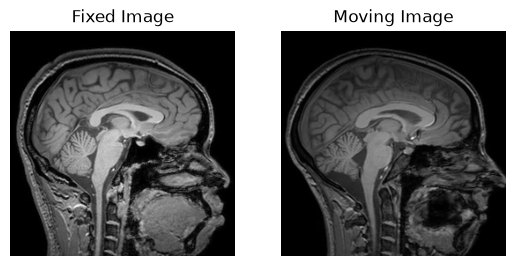

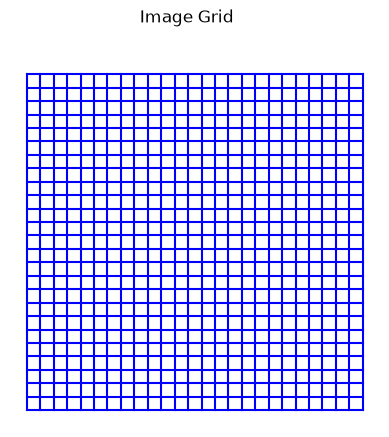

In [3]:
def visualize_image( ax, im, **kwargs ):
    # Visualize an image the same way the grid and vector fields are drawn: to the right means
    # x1 (row number in image matrix) goes up, and to the top means x2 (column number in image 
    # matrix) goes up.
    ax.imshow( np.flipud( im.T ), **kwargs )
    ax.set_aspect( 'equal' )
    ax.axis( False )

def plot_grid( ax, X1, X2, **kwargs ):
    for i in range(X1.shape[0]):
        ax.plot(X1[i,:], X2[i,:], **kwargs)
    for i in range(X1.shape[1]):
        ax.plot(X1[:,i], X2[:,i], **kwargs)

def visualize_grid( ax, X1, X2 ):
    N1, N2 = X1.shape
    plot_grid( ax, X1[ ::10, ::10 ], X2[ ::10, ::10 ], color='b' )
    ax.set_aspect( 'equal' )
    ax.axis( False )

fixed = np.flipud( fixed )
moving = np.flipud( moving )

fig, ax = plt.subplots( 1, 2 )
visualize_image( ax[0], fixed, cmap='gray' )
visualize_image( ax[1], moving, cmap='gray' )
ax[0].set_title("Fixed Image")
ax[1].set_title("Moving Image")

X1, X2 = np.meshgrid( np.arange(fixed.shape[0]), np.arange(fixed.shape[1]), indexing='ij' )
fig, ax = plt.subplots()
visualize_grid( ax, X1, X2 )
fig.suptitle("Image Grid")

In this exercise, you'll be asked to compute and display image histograms, and to indicate the location of a specific intensity value in the histogram plot. The code snippet below shows how this can be done:

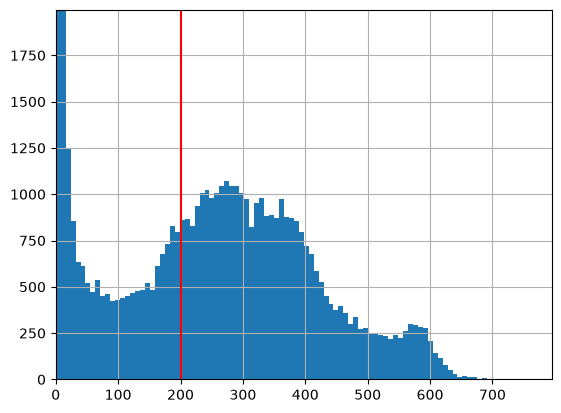

In [4]:
data = fixed
value = np.median( data )

histogram, edges = np.histogram( data.ravel(), bins=100 )
binCenters = ( edges[ 1: ] + edges[ :-1 ] ) / 2
binWidth = edges[ 1 ] - edges[ 0 ]
fig, ax = plt.subplots()
ax.bar( binCenters, histogram, width=binWidth )
ax.set_ylim( 0, histogram[1:].max() )  # clip the entry for background
ax.set_xlim( 0, data.max() )
ax.plot( [ value ]*2, ax.get_ylim(), 'r' )
ax.grid()


## Task 1: Normalize the intensity values of both images

Since MRI images are not calibrated, the pixel intensities in the fixed and the moving image are not necessarily comparable. As a first attempt to normalize the intensity values, divide each image by its maximum intensity value (to bring both images in the range $[0,1]$) and display both images, as well as their histograms, side by side. Are the intensity values now comparable between the two images?
> ***Hints:***
> - To avoid automatic rescaling of the visualization color map, you should perform the visualization as follows:
>        visualize_image( ax, fixed, cmap='gray', vmin=0, vmax=1 )

Compute a *robust* version of the maximum intensity in each image by locating the intensity value in the histogram so that 99% of the image pixels have a lower intensity. For each image, indicate the location of the value you find in the histogram using a verticle line (see code snippet given in the introduction).

Now rescale the image intensities again, this time using the robust maximum value instead. (Intensities higher than the robust maximum should be clipped so that all intensities fall within the range $[0,1]$ after intensity normalization.) Display both normalized images, as well as their histograms, side by side again. Decide which normalization method makes the image intensities more comparable, explain why, and perform the remainder of the exercise using the normalized images of your choice.

# Task 1: Solution


MRI intensities are not calibrated, so the same tissue can have different values in two scans. Before comparing the images with a sum-of-squared-differences measure, we bring both images to a common range [0, 1]. We try two methods:

1. **Max normalization:** divide each image by its maximum intensity.
2. **Robust max normalization:** divide each image by the intensity below which 99% of the pixels lie (the 99th percentile), then clip values above 1.

In [5]:
def plot_histogram(ax, data, value=None, bins=100, xmax=None, title=None):
    """Histogram of the pixel intensities, with an optional red vertical line at `value`."""
    histogram, edges = np.histogram(data.ravel(), bins=bins)
    binCenters = (edges[1:] + edges[:-1]) / 2
    binWidth = edges[1] - edges[0]
    ax.bar(binCenters, histogram, width=binWidth)
    # ignore the first bin (background) and last bin (clipped pixels) when scaling the y-axis
    ax.set_ylim(0, histogram[1:-1].max())
    ax.set_xlim(0, data.max() if xmax is None else xmax)
    if value is not None:
        ax.plot([value] * 2, ax.get_ylim(), 'r')
    ax.grid()
    if title is not None:
        ax.set_title(title)

def show_pair(fixed_im, moving_im, suptitle, vmax=1, xmax=1, values=(None, None)):
    """Show both images and their histograms side by side."""
    fig, ax = plt.subplots(2, 2, figsize=(10, 8))
    visualize_image(ax[0, 0], fixed_im, cmap='gray', vmin=0, vmax=vmax)
    visualize_image(ax[0, 1], moving_im, cmap='gray', vmin=0, vmax=vmax)
    ax[0, 0].set_title('Fixed image')
    ax[0, 1].set_title('Moving image')
    plot_histogram(ax[1, 0], fixed_im, values[0], xmax=xmax, title='Fixed histogram')
    plot_histogram(ax[1, 1], moving_im, values[1], xmax=xmax, title='Moving histogram')
    fig.suptitle(suptitle)
    fig.tight_layout()

def overlay_histograms(fixed_im, moving_im, title, bins=100):
    """Plot both histograms in one axis so the tissue peaks can be compared directly."""
    fig, ax = plt.subplots(figsize=(7, 4))
    for im, label in [(fixed_im, 'Fixed'), (moving_im, 'Moving')]:
        h, edges = np.histogram(im.ravel(), bins=bins, range=(0, 1))
        centers = (edges[1:] + edges[:-1]) / 2
        ax.plot(centers[1:-1], h[1:-1], label=label)  # skip background and clipped bins
    ax.set_xlim(0, 1)
    ax.set_xlabel('Normalized intensity')
    ax.set_ylabel('Pixel count')
    ax.set_title(title)
    ax.legend()
    ax.grid()

Max intensity fixed:  795.0
Max intensity moving: 1243.6


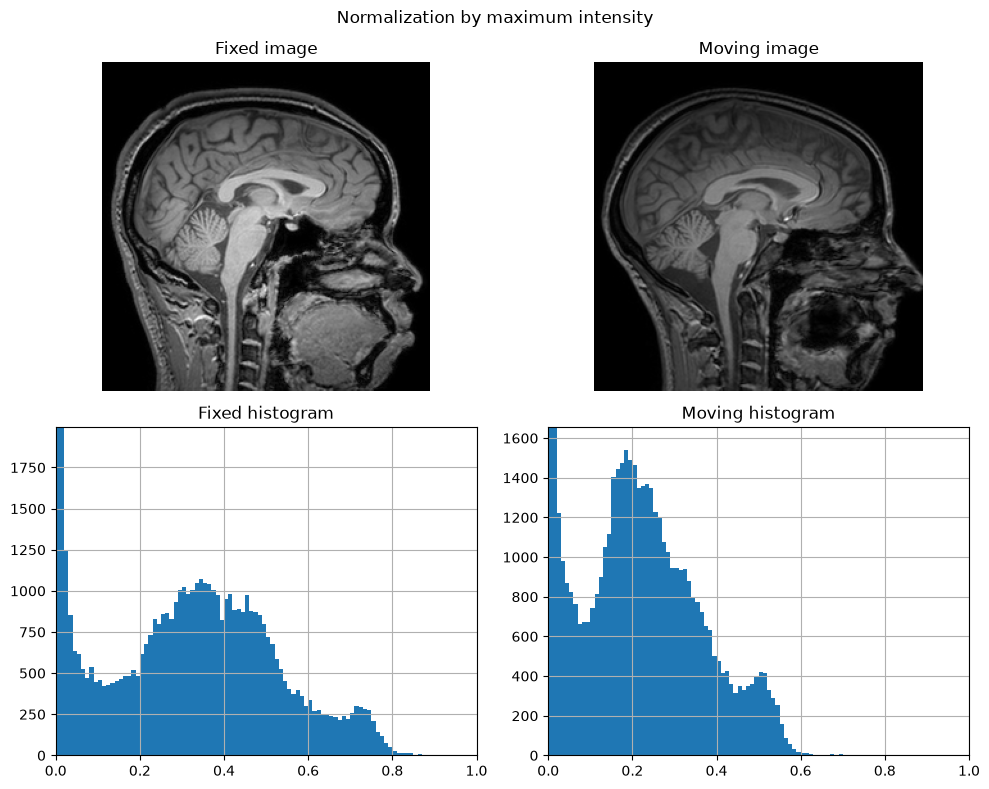

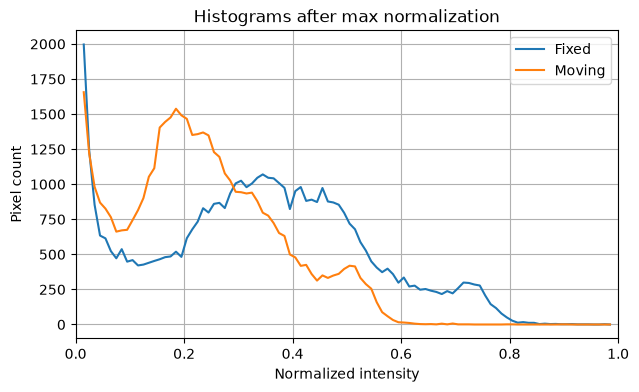

In [6]:
fixed_max = fixed / fixed.max()
moving_max = moving / moving.max()

print(f'Max intensity fixed:  {fixed.max():.1f}')
print(f'Max intensity moving: {moving.max():.1f}')

show_pair(fixed_max, moving_max, 'Normalization by maximum intensity')
overlay_histograms(fixed_max, moving_max, 'Histograms after max normalization')

Robust max fixed:  599.4  (check: 599.0)
Robust max moving: 672.8  (check: 672.0)


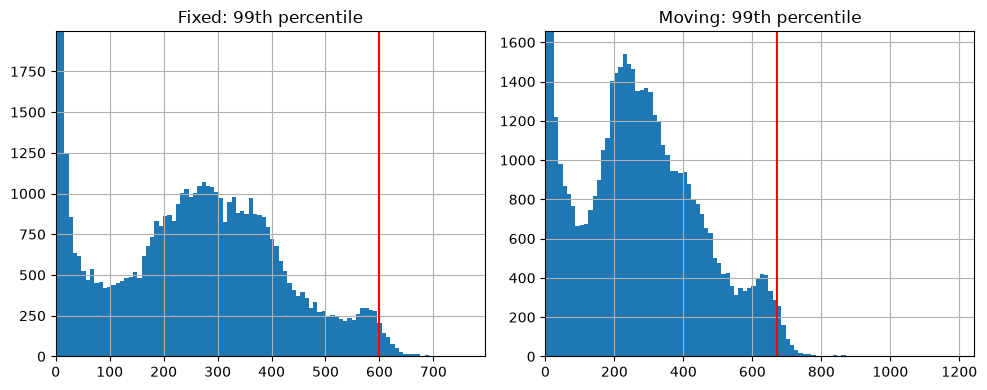

In [7]:
def robust_max(im, q=0.99, bins=1000):
    """Intensity below which a fraction q of the pixels lie, found from the cumulative histogram."""
    hist, edges = np.histogram(im.ravel(), bins=bins)
    cdf = np.cumsum(hist) / hist.sum()
    idx = np.searchsorted(cdf, q)  # first bin where the cumulative fraction reaches q
    return edges[idx + 1]          # upper edge of that bin

fixed_rmax = robust_max(fixed)
moving_rmax = robust_max(moving)

print(f'Robust max fixed:  {fixed_rmax:.1f}  (check: {np.percentile(fixed, 99):.1f})')
print(f'Robust max moving: {moving_rmax:.1f}  (check: {np.percentile(moving, 99):.1f})')

# histograms of the ORIGINAL images with the robust max marked
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_histogram(ax[0], fixed, fixed_rmax, title='Fixed: 99th percentile')
plot_histogram(ax[1], moving, moving_rmax, title='Moving: 99th percentile')
fig.tight_layout()

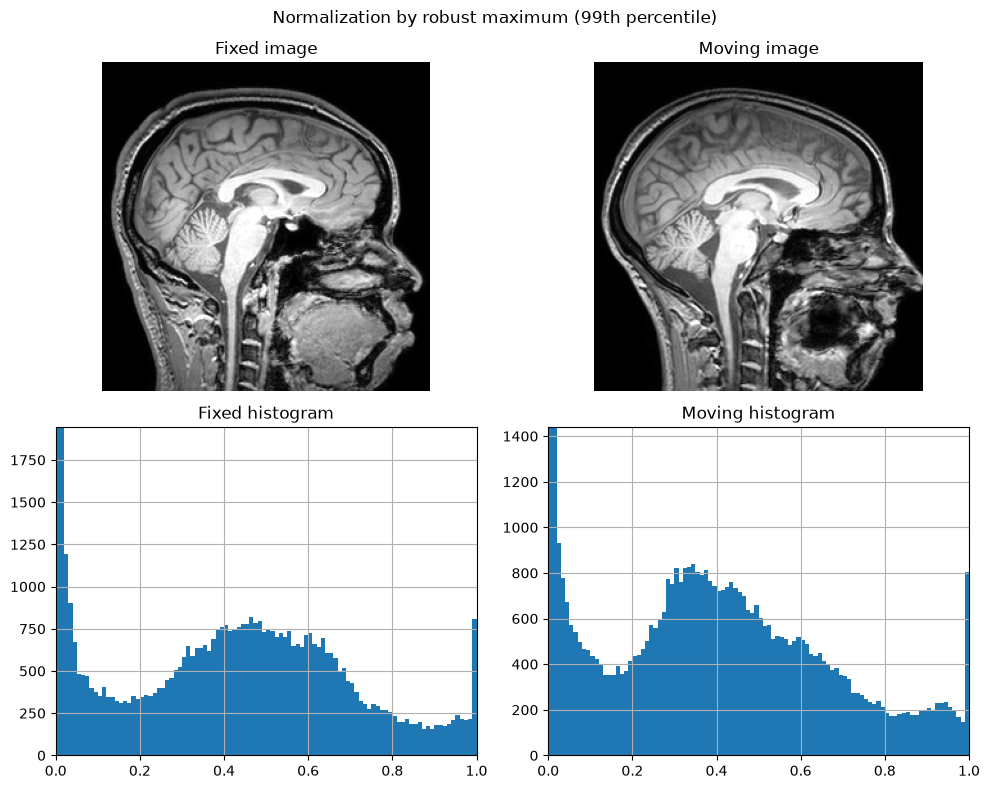

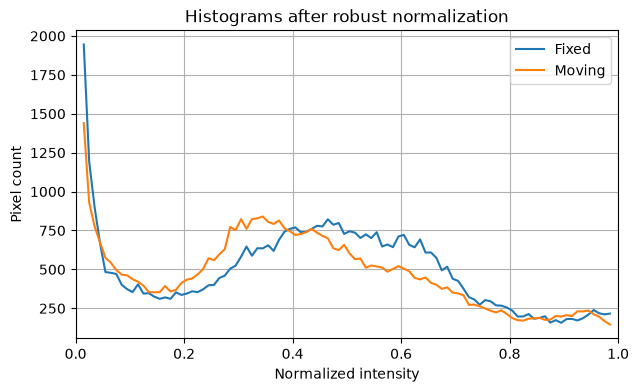

In [8]:
fixed_robust = np.clip(fixed / fixed_rmax, 0, 1)
moving_robust = np.clip(moving / moving_rmax, 0, 1)

show_pair(fixed_robust, moving_robust, 'Normalization by robust maximum (99th percentile)')
overlay_histograms(fixed_robust, moving_robust, 'Histograms after robust normalization')

In [9]:
# Robust normalization is used for Tasks 2-5
fixed = fixed_robust
moving = moving_robust

**Max normalization.** Dividing by the maximum maps both images to [0, 1], but the two histograms end up very differently distributed.
- In the fixed image, the tissue intensities spread over roughly 0.2–0.8, with the main peak around 0.35–0.45 and a smaller bright bump around 0.72.
- In the moving image, almost all tissue lies below 0.6: the main peak is at about 0.2 and the bright bump at about 0.5.

The moving image's maximum is apparently set by a few very bright outlier pixels well above its tissue intensities. As a result, all of its tissue is squeezed into the lower part of the range. The overlaid histograms show that the same tissue has clearly different normalized intensities in the two images, so max normalization does **not** make them comparable.

**Robust normalization.** The 99th percentile ignores the brightest 1% of pixels, so it depends on the tissue intensities rather than on single outliers. After dividing by this value and clipping, both images use the full [0, 1] range. The two histograms now have very similar shapes:
- The background parts overlap almost perfectly, and so do the bright tails between 0.7 and 1.0.
- The main tissue peaks are much closer together, at about 0.33 (moving) and 0.45 (fixed).
- The spike at 1.0 in each histogram contains the roughly 1% of pixels that were clipped.

The normalized images also look similar in brightness and contrast.

A small offset between the main peaks remains. A single linear scaling cannot remove it, because the two slices contain somewhat different amounts of each tissue (e.g. the mouth and neck region looks quite different). The MR contrast of the two scans may also differ slightly. Removing this offset would require a nonlinear intensity mapping, such as histogram matching. The match is nevertheless much better than with max normalization.

**Choice.** We use the robust normalization for the rest of the exercise. The SSD registration energy assumes that corresponding tissues have the same intensity in both images, and robust normalization satisfies this assumption much better. The only cost is that the brightest 1% of pixels saturate at 1, which mostly affects small bright structures such as fat and vessels.

## Task 2: Create basis functions for nonlinear deformation
In order to model the residual deformation in each direction $d=1,\ldots,D$, you are going to use a weighted set of basis functions:
$$
\delta_d(\mathbf{x}, \mathbf{w}_d) = \sum_{m=0}^{M-1} w_{d,m}\phi_m (\mathbf{x})
.
$$
Here $\phi_m (\mathbf{x})$ are $M$ basis functions, and $\mathbf{w}_d$ are the weights for direction $d$. 
For the purpose of this exercise, construct a set of $M=7 \times 7=49$ separable, 2D cubic B-spline basis functions that cover the image area of the fixed image. Include a visualization of the basis functions, plotted in a $7 \times 7$ grid, in your report.

> ***Hint:***
> - You should reuse the code for the 2D B-Spline basis functions that you implemented for the exercise about image smoothing.

For the purpose of the exercise, retain only the central part of $5 \times 5$ basis functions, removing all the B-splines that are centered on one of the image edges. This will avoid strangle-looking, large deformations of the image edges later on.

> ***Hint:***
> - There are several ways of doing this. One option is to construct the 25 2D basis functions from only the 5 central 1D basis functions in each direction to start with:  
>        np.kron( Phi2[:,1:-1], Phi1[:,1:-1] ) 
> instead of 
>        np.kron( Phi2, Phi1 )


## Task 2: Solution


The residual deformation in each direction $d$ is modeled as a weighted sum of $M$ basis functions:
$$
\delta_d(\mathbf{x}, \mathbf{w}_d) = \sum_{m=0}^{M-1} w_{d,m}\,\phi_m(\mathbf{x}),
\qquad \text{or in matrix form} \qquad \boldsymbol{\delta}_d = \boldsymbol{\Phi}\,\mathbf{w}_d ,
$$
where each column of the $N \times M$ matrix $\boldsymbol{\Phi}$ holds one basis function evaluated at all $N$ pixels.

**1D basis.** We use uniform cubic B-splines
$$
B(t) =
\begin{cases}
\tfrac{2}{3} - t^2 + \tfrac{1}{2}|t|^3, & |t| < 1 \\
\tfrac{1}{6}(2 - |t|)^3, & 1 \le |t| < 2 \\
0, & \text{otherwise}
\end{cases}
$$
and define $\phi_m(x) = B\big((x - c_m)/h\big)$. The $M$ centers $c_m$ are evenly spaced over the image, from the first pixel to the last, with spacing $h = (N-1)/(M-1)$. Each function is smooth, has local support (4 knot intervals), and is non-negative.

**2D basis.** The 2D basis functions are separable products $\phi_{m_1,m_2}(\mathbf{x}) = \phi_{m_1}(x_1)\,\phi_{m_2}(x_2)$. If $\boldsymbol{\Phi}_1$ ($N_1 \times M_1$) and $\boldsymbol{\Phi}_2$ ($N_2 \times M_2$) contain the 1D basis functions, all products are obtained at once with the Kronecker product $\boldsymbol{\Phi} = \boldsymbol{\Phi}_2 \otimes \boldsymbol{\Phi}_1$. In this ordering $x_1$ varies fastest, so a column of $\boldsymbol{\Phi}$ is reshaped into an image in Fortran (column-major) order. All image vectors in later tasks must use the same ordering.

We first construct and display the full $7 \times 7 = 49$ basis functions. We then keep only the central $5 \times 5 = 25$, dropping the B-splines centered on the image edges, to avoid large deformations at the borders.

In [10]:
def bspline3(t):
    """Uniform cubic B-spline evaluated at t."""
    t = np.abs(t)
    out = np.zeros_like(t, dtype=float)
    inner = t < 1
    outer = (t >= 1) & (t < 2)
    out[inner] = 2/3 - t[inner]**2 + 0.5 * t[inner]**3
    out[outer] = (2 - t[outer])**3 / 6
    return out

def bspline_basis_1d(N, M):
    """N x M matrix: M cubic B-splines with centers evenly spaced over 0..N-1."""
    x = np.arange(N)
    h = (N - 1) / (M - 1)               # spacing between centers
    centers = np.arange(M) * h
    return bspline3((x[:, None] - centers[None, :]) / h)

def bspline_basis_2d(N1, N2, M1, M2, remove_edges=True):
    """(N1*N2) x (number of basis functions) matrix of separable 2D B-splines.
    Rows are ordered with x1 varying fastest (Fortran order)."""
    Phi1 = bspline_basis_1d(N1, M1)
    Phi2 = bspline_basis_1d(N2, M2)
    if remove_edges:
        Phi1, Phi2 = Phi1[:, 1:-1], Phi2[:, 1:-1]
    return np.kron(Phi2, Phi1)

N1, N2 = fixed.shape
print('Image size:', N1, 'x', N2)

Image size: 256 x 256


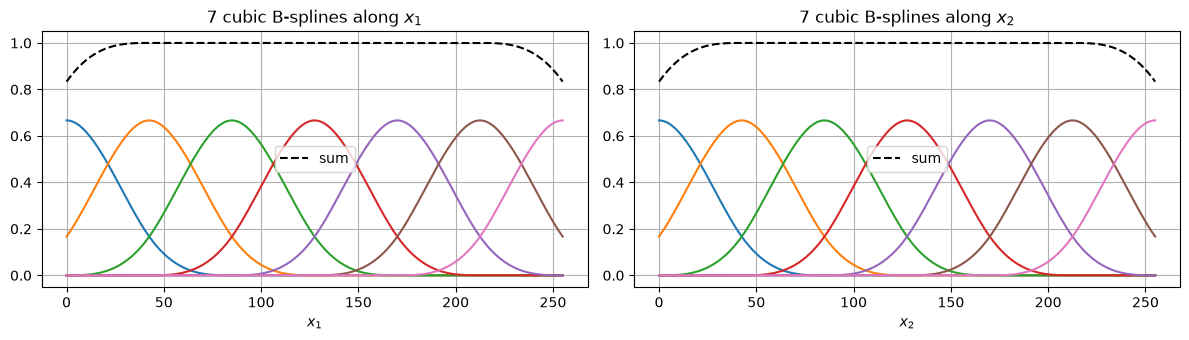

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, N, label in [(ax[0], N1, '$x_1$'), (ax[1], N2, '$x_2$')]:
    Phi_1d = bspline_basis_1d(N, 7)
    a.plot(np.arange(N), Phi_1d)
    a.plot(np.arange(N), Phi_1d.sum(axis=1), 'k--', label='sum')
    a.set_xlabel(label)
    a.set_title(f'7 cubic B-splines along {label}')
    a.legend()
    a.grid()
fig.tight_layout()

Full basis matrix: (65536, 49)


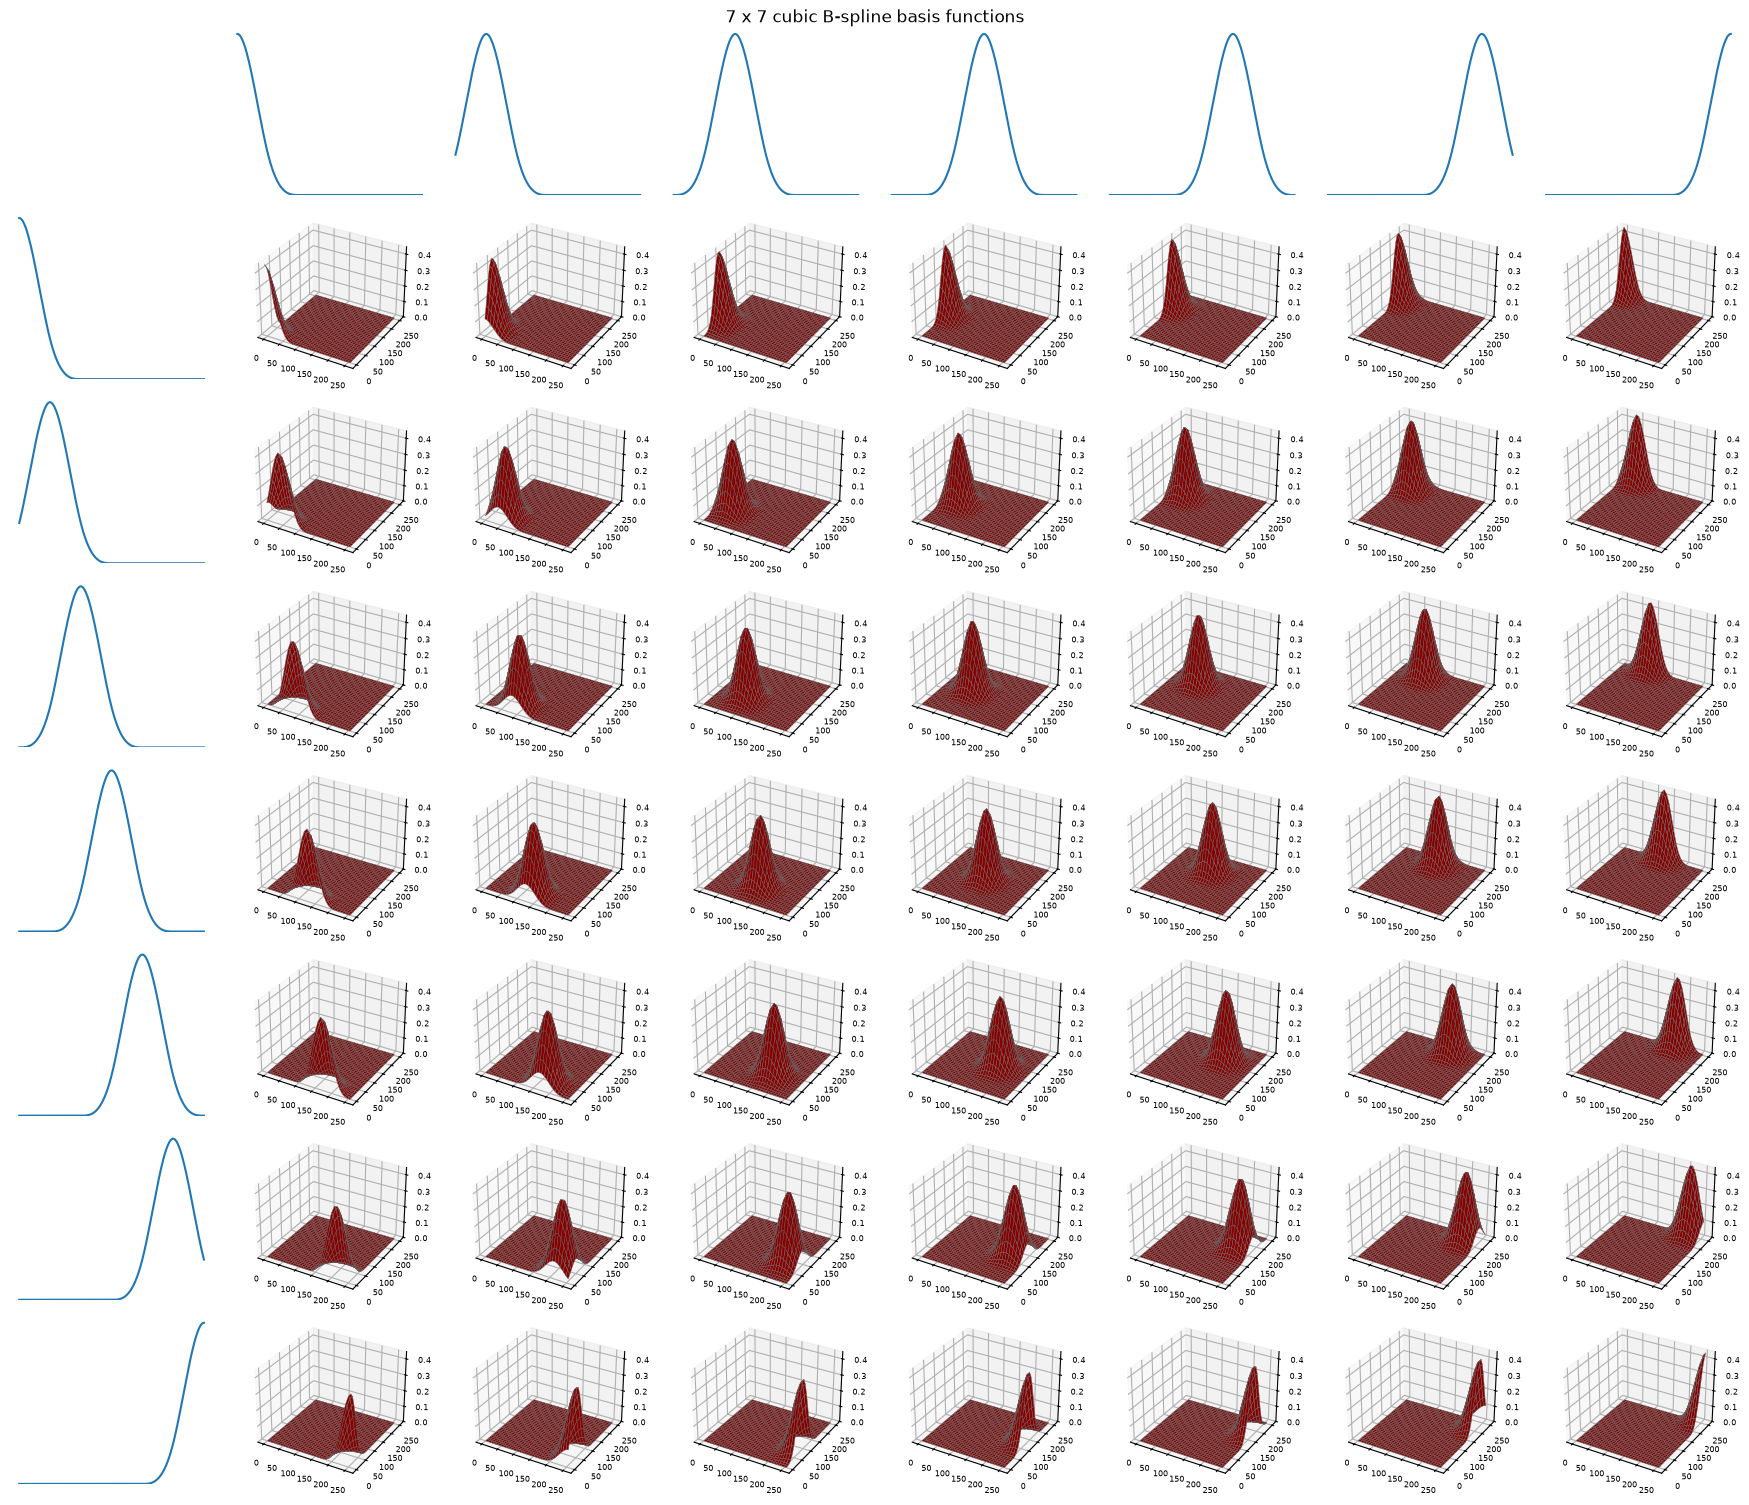

In [14]:
def show_basis_grid_3d(Phi, Phi1, Phi2, title, step=8):
    """Plot the 2D basis functions as 3D surfaces in a grid.
    The top row shows the 1D basis functions along x2 (one per column), and the left
    column shows the 1D basis functions along x1 (one per row). Each interior panel
    shows the corresponding column of Phi, i.e. the product of its row and column functions."""
    N1, K1 = Phi1.shape
    N2, K2 = Phi2.shape

    # downsampled grid for the surface plots (always include the last pixel)
    i1 = np.r_[0:N1:step, N1 - 1]
    i2 = np.r_[0:N2:step, N2 - 1]
    X1s, X2s = np.meshgrid(i1, i2, indexing='ij')

    fig = plt.figure(figsize=(2.2 * (K2 + 1), 1.9 * (K1 + 1)))
    gs = fig.add_gridspec(K1 + 1, K2 + 1)
    ymax = max(Phi1.max(), Phi2.max()) * 1.05
    zmax = Phi.max()

    # top row: 1D basis functions along x2
    for j in range(K2):
        ax = fig.add_subplot(gs[0, j + 1])
        ax.plot(np.arange(N2), Phi2[:, j])
        ax.set_ylim(0, ymax)
        ax.axis('off')

    # left column: 1D basis functions along x1
    for i in range(K1):
        ax = fig.add_subplot(gs[i + 1, 0])
        ax.plot(np.arange(N1), Phi1[:, i])
        ax.set_ylim(0, ymax)
        ax.axis('off')

    # interior: 2D basis functions taken directly from the columns of Phi
    for i in range(K1):          # index along x1
        for j in range(K2):      # index along x2
            m = j * K1 + i       # column of Phi (Kronecker ordering: x1 varies fastest)
            phi = Phi[:, m].reshape((N1, N2), order='F')
            ax = fig.add_subplot(gs[i + 1, j + 1], projection='3d')
            ax.plot_surface(X1s, X2s, phi[np.ix_(i1, i2)],
                            color='red', edgecolor='dimgray', linewidth=0.3)
            ax.set_zlim(0, zmax)
            ax.tick_params(labelsize=6, pad=0)

    fig.suptitle(title)
    fig.tight_layout()

    # full 7 x 7 set
P1_full = bspline_basis_1d(N1, 7)
P2_full = bspline_basis_1d(N2, 7)
Phi_full = bspline_basis_2d(N1, N2, 7, 7, remove_edges=False)
print('Full basis matrix:', Phi_full.shape)
show_basis_grid_3d(Phi_full, P1_full, P2_full, '7 x 7 cubic B-spline basis functions')

The 1D plot shows the 7 cubic B-splines along each axis. Each one is a smooth bump with local support, and together they sum to one in the interior of the image (partition of unity). The 7 × 7 grid shows the separable 2D basis functions, each a smooth blob centered on a regular grid over the image. The functions on the border rows and columns are centered on the image edges, so only half of their bump lies inside the image.

We keep only the central 5 × 5 functions. The sum image shows that the retained functions still cover the interior of the image, while their combined weight falls to zero at the image edges. The resulting deformation $\boldsymbol{\Phi}\mathbf{w}_d$ is therefore always zero at the border, which prevents large deformations of the image edges. The basis matrix $\boldsymbol{\Phi}$ has size $N \times 25$, with $N = N_1 N_2$ pixels.

## Task 3: Manipulate the image locally with basis function

In this task, you will use two weight vectors $\mathbf{w}_1$ and $\mathbf{w}_2$ to control the transformation model 
$$ 
y_d(\mathbf{x}, \mathbf{w}_d) = x_d + \delta_d(\mathbf{x}, \mathbf{w}_d), \quad d=1,2
,
$$
and visualize the effect of changing these weights on the resulting image deformation.
For each choice of weights, you should show (1) how a regular image grid defined in the space of the fixed image looks after deformation, and (2) the corresponding interpolated moving image, resampled to the image grid of the fixed image.

In a first experiment, set all elements of $\mathbf{w}_2$ to zero, and set all elements *except one* in $\mathbf{w}_1$ to zero. Try a few different values for the one non-zero entry, show each time the resulting deformated image grid and the interpolated moving image, and comment on what you see. 

In a second experiment, apply a non-zero value to the corresponding (i.e., controlling the same 2D basis function) element in $\mathbf{w}_2$ as well. Again visualize the result and comment.

> ***Hints:***
> - Plot the deformed grid with the function visualize_grid() provided in the introduction, following the example of the non-deformed grid that was given. 
> - View your deformed moving image with the function visualize_image() that was provided.

## Task 3: Solution


The transformation model maps each pixel $\mathbf{x}$ of the fixed image to a location in the moving image:
$$
y_d(\mathbf{x}, \mathbf{w}_d) = x_d + \delta_d(\mathbf{x}, \mathbf{w}_d), \qquad d = 1, 2 .
$$
In vector form, this is $\mathbf{y}_d = \mathbf{x}_d + \boldsymbol{\Phi}\mathbf{w}_d$ for all $N$ pixels at once. The deformed moving image is obtained by interpolating the moving image at the mapped locations, $\mathcal{M}(\mathbf{y}(\mathbf{x}_n, \mathbf{w}))$, and placing the results on the pixel grid of the fixed image.

For each choice of weights we show:
- the regular image grid of the fixed image after it has been mapped into the moving image space (the points $\mathbf{y}$),
- the moving image resampled onto the grid of the fixed image.

Both experiments use the central basis function of the $5 \times 5$ set. Its center is marked with a red dot in the grid plots.

In [16]:
# pixel coordinates of the fixed image, flattened in the same (Fortran) order as the rows of Phi
X1, X2 = np.meshgrid(np.arange(N1), np.arange(N2), indexing='ij')
x1 = X1.ravel(order='F')
x2 = X2.ravel(order='F')

K1 = K2 = 5                                   # number of retained basis functions per direction
c1 = np.arange(1, K1 + 1) * (N1 - 1) / 6      # centers of the central B-splines along x1
c2 = np.arange(1, K2 + 1) * (N2 - 1) / 6      # centers of the central B-splines along x2

def transform(w1, w2, Phi=Phi):
    """Mapped coordinates y_d = x_d + Phi w_d for all pixels (flattened)."""
    return x1 + Phi @ w1, x2 + Phi @ w2

def warp(image, y1, y2):
    """Interpolate `image` at the mapped coordinates and reshape to the fixed image grid."""
    return map_coordinates(image, [y1, y2]).reshape((N1, N2), order='F')

def show_deformation(w1, w2, title, m=None):
    y1, y2 = transform(w1, w2)
    Y1 = y1.reshape((N1, N2), order='F')
    Y2 = y2.reshape((N1, N2), order='F')
    warped = warp(moving, y1, y2)

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    visualize_image(ax[0], moving, cmap='gray', vmin=0, vmax=1)
    ax[0].set_title('Original moving image')
    visualize_grid(ax[1], Y1, Y2)
    ax[1].set_xlim(-15, N1 + 15)
    ax[1].set_ylim(-15, N2 + 15)
    if m is not None:
        ax[1].plot(c1[m % K1], c2[m // K1], 'ro')
    ax[1].set_title('Deformed grid')
    visualize_image(ax[2], warped, cmap='gray', vmin=0, vmax=1)
    ax[2].set_title('Deformed moving image')

    d1, d2 = Phi @ w1, Phi @ w2
    fig.suptitle(f'{title}\nmax |displacement|: '
                 f'{np.max(np.sqrt(d1**2 + d2**2)):.1f} pixels')
    fig.tight_layout()

m = 12        # central basis function (m1 = 2, m2 = 2)

In [17]:
# The transformation stays one-to-one along x1 as long as 1 + w * dphi/dx1 > 0 everywhere,
# i.e. |w| < 1 / max|dphi/dx1|. Compute this limit for the chosen basis function.
phi_m = Phi[:, m].reshape((N1, N2), order='F')
dphi_dx1 = np.gradient(phi_m, axis=0)
w_fold = 1 / np.abs(dphi_dx1).max()
print(f'Peak value of basis function {m}: {phi_m.max():.3f}')
print(f'Folding occurs for |w| > {w_fold:.0f}')

Peak value of basis function 12: 0.444
Folding occurs for |w| > 96


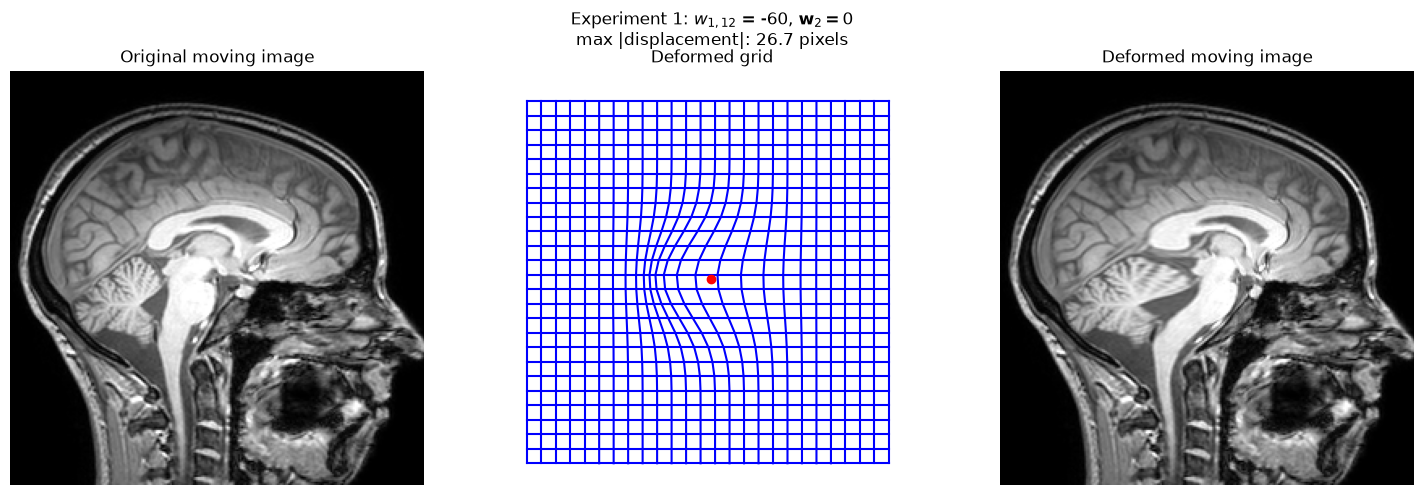

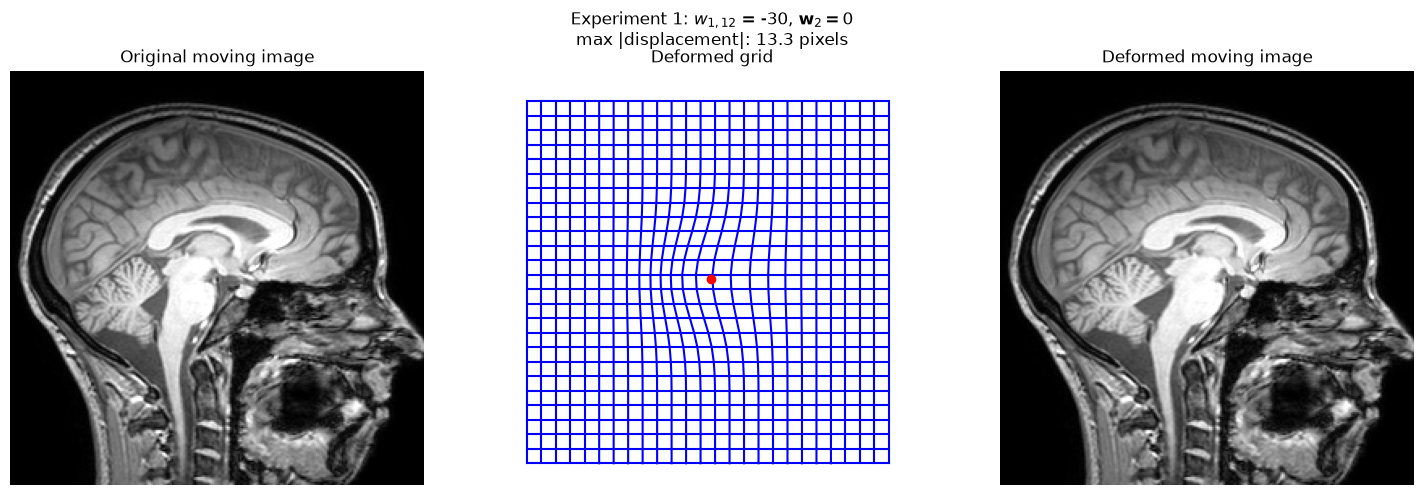

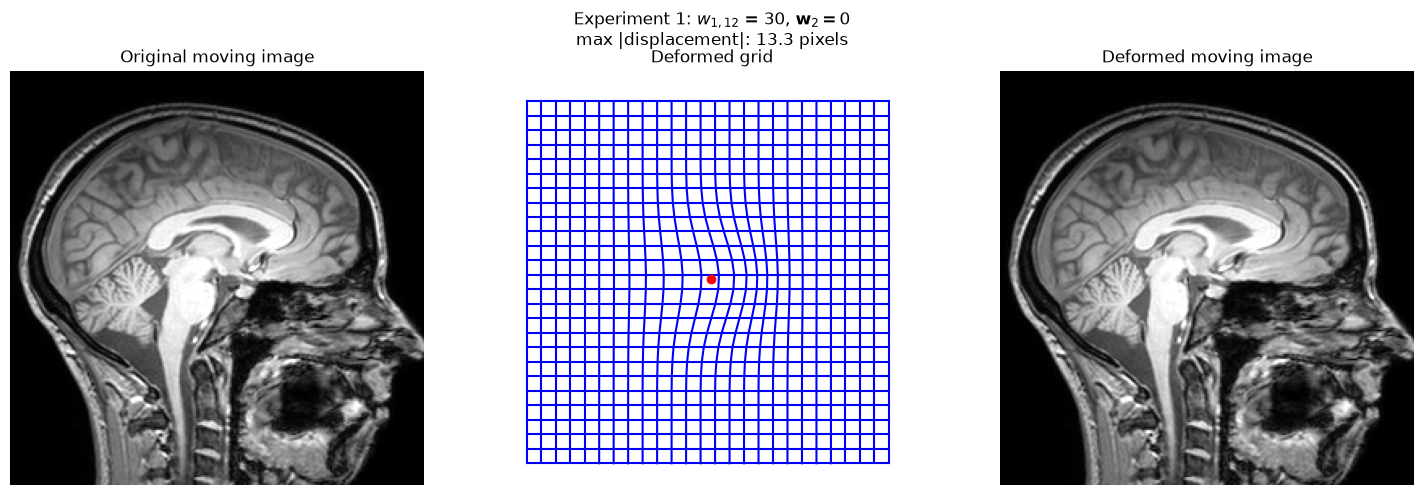

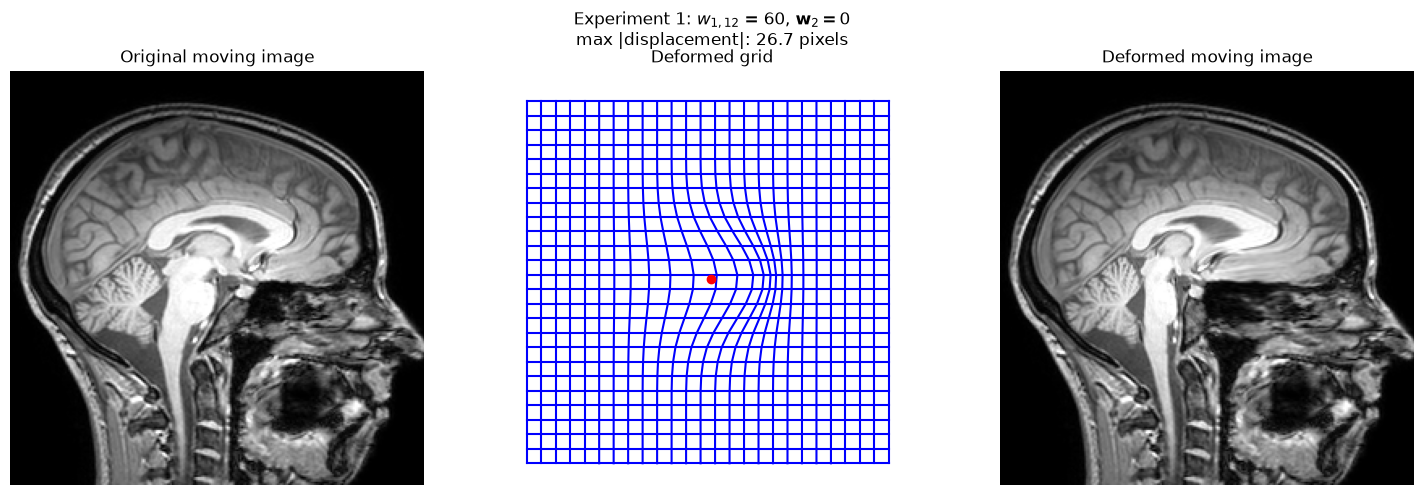

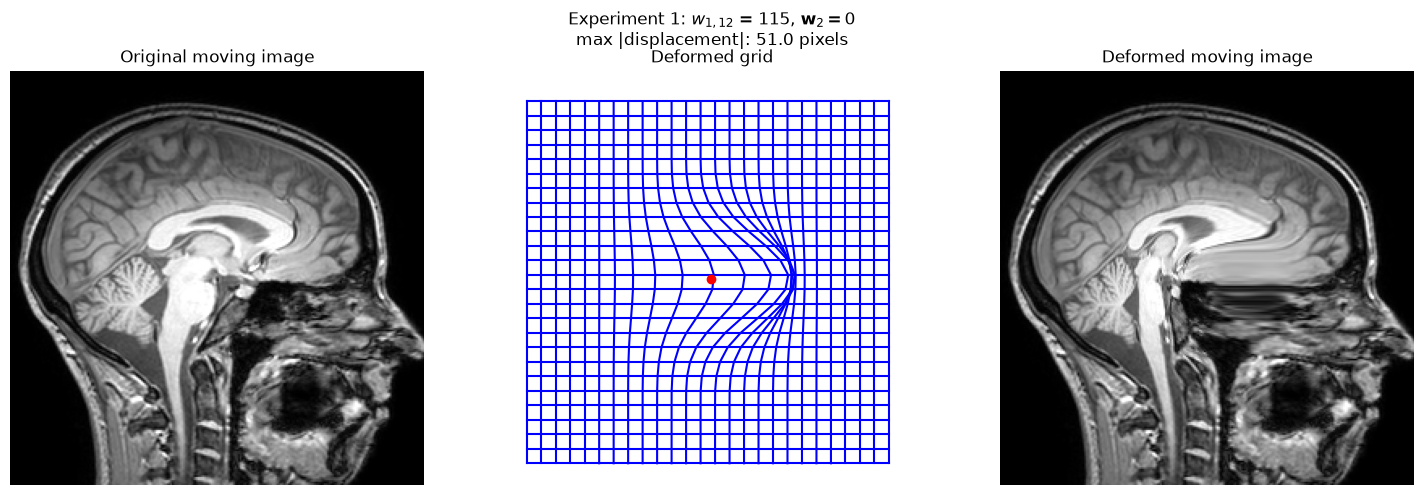

In [18]:
for value in [-60, -30, 30, 60, 1.2 * w_fold]:
    w1 = np.zeros(M)
    w2 = np.zeros(M)
    w1[m] = value
    show_deformation(w1, w2, f'Experiment 1: $w_{{1,{m}}}$ = {value:.0f}, $\\mathbf{{w}}_2 = 0$', m)

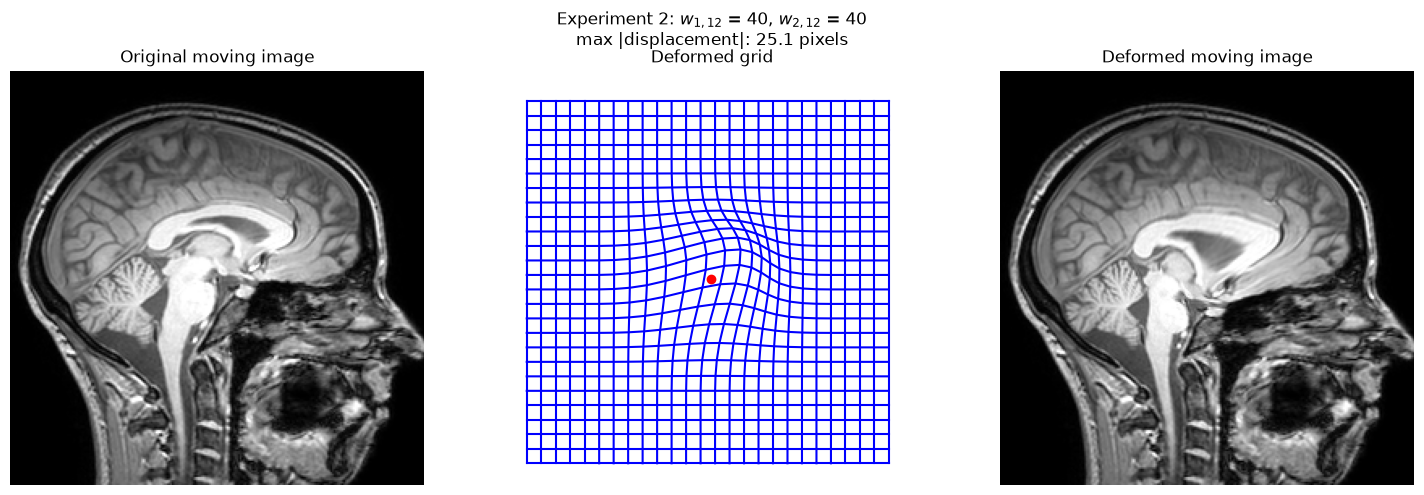

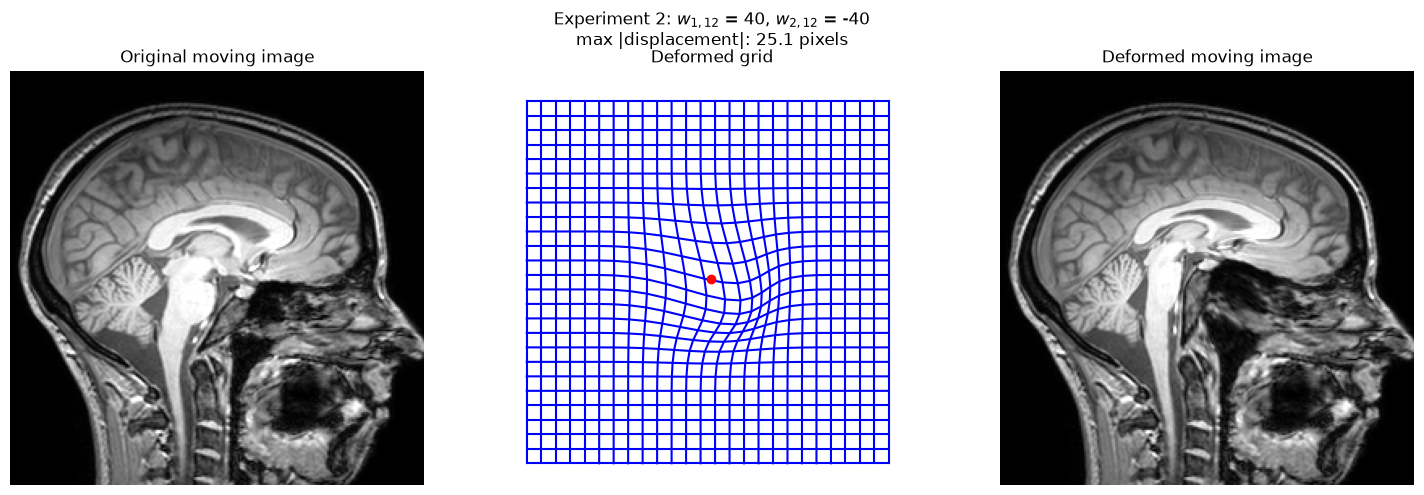

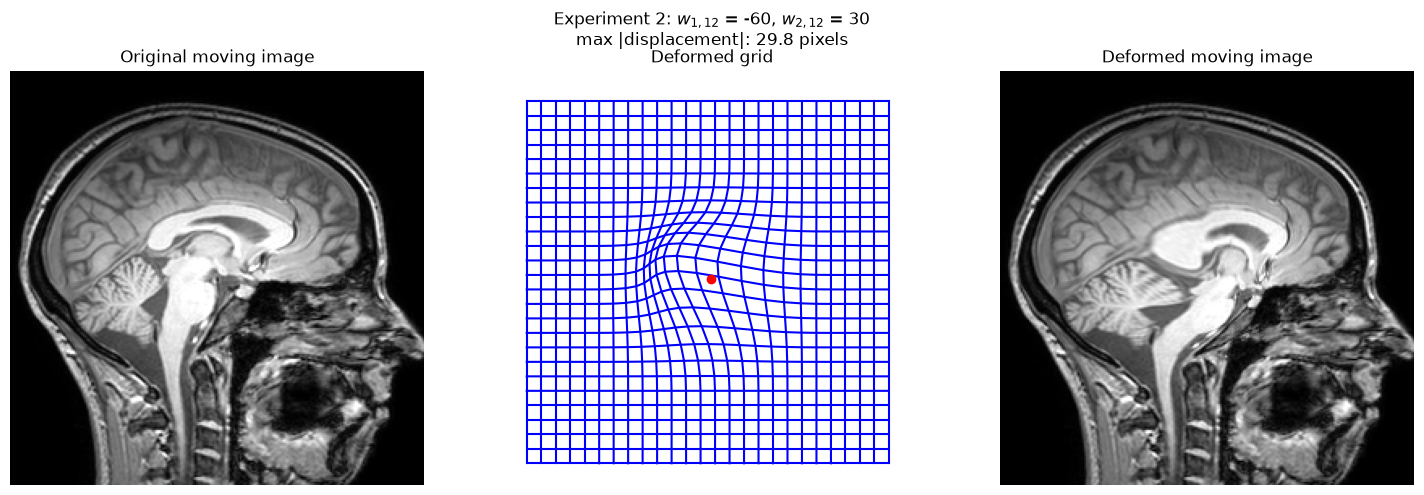

In [19]:
for v1, v2 in [(40, 40), (40, -40), (-60, 30)]:
    w1 = np.zeros(M)
    w2 = np.zeros(M)
    w1[m] = v1
    w2[m] = v2
    show_deformation(w1, w2, f'Experiment 2: $w_{{1,{m}}}$ = {v1}, $w_{{2,{m}}}$ = {v2}', m)

**Experiment 1: one non-zero weight in $\mathbf{w}_1$.**
- The displacement field is $\boldsymbol{\delta}_1 = w_{1,m}\,\boldsymbol{\phi}_m$ and $\boldsymbol{\delta}_2 = \mathbf{0}$, so the deformation acts only along $x_1$ (horizontally in the figures). It has the shape of the chosen basis function: largest at its center and fading smoothly to zero outside its support. The rest of the image, including the borders, is unaffected.
- A positive weight moves the grid points around the center to the right, so pixels there sample the moving image further to the right. In the resampled image, the anatomy around the center therefore appears shifted to the *left*. A negative weight has the opposite effect. The grid shows where each fixed-image pixel looks in the moving image, while the resampled image shows the result on the fixed grid. That is why the two appear to move in opposite directions.
- Because the displacement varies smoothly in space, the image is not simply shifted: one side of the bump is stretched and the other is compressed.
- The size of the effect scales linearly with the weight. The peak displacement equals the weight times the peak of the basis function (≈ 0.44).
- When the weight exceeds the computed limit (last figure), $1 + w\,\partial\phi_m/\partial x_1$ becomes negative in part of the image. The grid lines then cross each other (folding) and the resampled image shows duplicated, mirrored structures. The transformation is no longer one-to-one there, which is not physically plausible. Weights in a registration should stay well below this limit.

**Experiment 2: corresponding non-zero weights in both $\mathbf{w}_1$ and $\mathbf{w}_2$.** Both displacement components now share the same spatial profile $\boldsymbol{\phi}_m$, so the local displacement at every pixel points in the direction $(w_{1,m}, w_{2,m})$ with magnitude proportional to $\phi_m$.
- With $w_1 = w_2$ the region around the center is pushed diagonally.
- With opposite signs it is pushed along the other diagonal.
- Different magnitudes give other directions.

One basis function with two weights thus produces a smooth, localized displacement in any direction. Combining many basis functions with different weights allows general smooth nonlinear deformations, which is what the registration in Task 4 will estimate.


## Task 4: Implement Gauss-Newton optimization
Search for the weight vector $\mathbf{w} = (\mathbf{w}_1, \mathbf{w}_2)^T$ that minimizes the sum-of-squared-differences energy
$$
E(\mathbf{w}) = \sum_{n=1}^N \left[ \mathcal{F}(\mathbf{x}_n) - \mathcal{M}(\mathbf{y}(\mathbf{x}_n, \mathbf{w})) \right]^2
,
$$
using the Gauss-Newton algorithm described on page 24-25 in the book.
Start from a zero weight vector $\mathbf{w}$ (corresponding to no deformation), and update $\mathbf{w}$ for 100 iterations. For the first and every 20-th subsequent iteration, show both the deformed image grid and the resampled moving image. Also plot how the energy changes across all the 100 iterations.

> ***Hints:***
> - Use a $\mathbf{\delta}$ step value of e.g. $0.001$
> - The diagonal elements of the matrix $\mathbf{G}_1$ contain partial spatial derivatives of the moving image in the first dimension (row direction). If y1 and y2 are vectors containing the mapped coordinates (first and second dimension, respectively) of all $N$ pixels of the fixed image, these diagonal elements can be approximated using 
>        
>   ( map_coordinates( moving, [ y1 + delta, y2 ] ) - map_coordinates( moving, [ y1, y2 ] ) ) / delta
>
>     for a small value of delta. The same applies to $\mathbf{G}_2$ (where delta is added to y2 instead of y1).
> - For an efficient implementation, it is worth considering what the effect is of $\mathbf{G}_d \boldsymbol{\Phi}$ on $\boldsymbol{\Phi}$ *without* implementing it literally as a matrix product.
> - If you find that the energy does not consistently go down across the iterations (by visual inspection of the energy curve), you can try to implement the Levenberg-Marquardt variant described in the book.


## Task 5: Experiment with different numbers of Basis Functions

Re-run the registration when the number of basis functions is altered (e.g., $3x3$ or $7x7$ instead of $5x5$) and inspect the outcomes. In your report, comment on differences in the results.